In [1]:
import pandas as pd
import numpy as np
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt

print("Day 2 environment ready!")

Day 2 environment ready!


In [2]:
file_path = "../data/online_retail_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (536641, 9)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

for col in ["Quantity", "UnitPrice", "Revenue", "CustomerID"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
Revenue               float64
dtype: object


In [4]:
sales = df[
    (df["CustomerID"].notna()) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()

sales["CustomerID"] = sales["CustomerID"].astype("int64")

print("Rows for analysis:", len(sales))
print("Identified customers:", sales["CustomerID"].nunique())
print("Unique invoices:", sales["InvoiceNo"].nunique())

Rows for analysis: 392692
Identified customers: 4338
Unique invoices: 18532


In [5]:
db_path = "../data/ecommerce.db"

conn = sqlite3.connect(db_path)

sales.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("SQL database created successfully!")

SQL database created successfully!


In [6]:
query = """
SELECT *
FROM sales
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [7]:
query = """
SELECT
    COUNT(*) AS total_sales_rows,
    COUNT(DISTINCT InvoiceNo) AS total_invoices,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales;
"""

pd.read_sql_query(query, conn)

,total_sales_rows,total_invoices,total_revenue
0,392692,18532,8887208.89


In [8]:
query = """
SELECT
    Description,
    SUM(Quantity) AS units_sold,
    ROUND(SUM(Revenue), 2) AS sales_revenue
FROM sales
GROUP BY Description
ORDER BY units_sold DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Description,units_sold,sales_revenue
0,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41
3,JUMBO BAG RED RETROSPOT,46078,85040.54
4,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.10
5,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03
6,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88
7,POPCORN HOLDER,30919,23417.51
8,RABBIT NIGHT LIGHT,27153,51251.24
9,MINI PAINT SET VINTAGE,26076,16039.24


In [9]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS sales_revenue,
    COUNT(DISTINCT InvoiceNo) AS total_invoices
FROM sales
GROUP BY Country
ORDER BY sales_revenue DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Country,sales_revenue,total_invoices
0,United Kingdom,7285024.64,16646
1,Netherlands,285446.34,94
2,EIRE,265262.46,260
3,Germany,228678.40,457
4,France,208934.31,389
5,Australia,138453.81,57
6,Spain,61558.56,90
7,Switzerland,56443.95,51
8,Belgium,41196.34,98
9,Sweden,38367.83,36


In [10]:
query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(Revenue), 2) AS monthly_revenue
FROM sales
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY month;
"""

monthly_sql = pd.read_sql_query(query, conn)
monthly_sql

,month,monthly_revenue
0,2010-12,570422.73
1,2011-01,568101.31
2,2011-02,446084.92
3,2011-03,594081.76
4,2011-04,468374.33
5,2011-05,677355.15
6,2011-06,660046.05
7,2011-07,598962.90
8,2011-08,644051.04
9,2011-09,950690.20


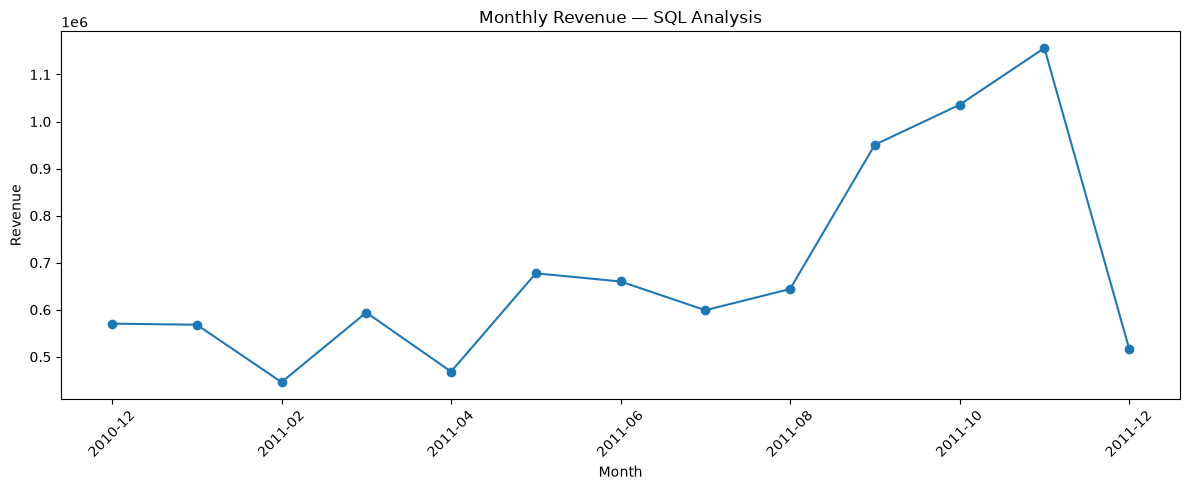

In [11]:
monthly_sql.plot(
    x="month",
    y="monthly_revenue",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False
)

plt.title("Monthly Revenue — SQL Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
query = """
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS total_spending,
    COUNT(DISTINCT InvoiceNo) AS number_of_orders
FROM sales
GROUP BY CustomerID
ORDER BY total_spending DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, conn)
top_customers

,CustomerID,total_spending,number_of_orders
0,14646,280206.02,73
1,18102,259657.30,60
2,17450,194390.79,46
3,16446,168472.50,2
4,14911,143711.17,201
5,12415,124914.53,21
6,14156,117210.08,55
7,17511,91062.38,31
8,16029,80850.84,63
9,12346,77183.60,1


In [13]:
reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = sales.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

rfm["Monetary"] = rfm["Monetary"].round(2)

print("RFM table shape:", rfm.shape)
rfm.head(10)

RFM table shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


In [14]:
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [15]:
repeat_customers = rfm[rfm["Frequency"] >= 2]

print("Total identified customers:", len(rfm))
print("Customers with 2+ invoices:", len(repeat_customers))

if len(rfm) > 0:
    repeat_pct = len(repeat_customers) / len(rfm) * 100
    print("Repeat customer percentage:", round(repeat_pct, 2), "%")

Total identified customers: 4338
Customers with 2+ invoices: 2845
Repeat customer percentage: 65.58 %


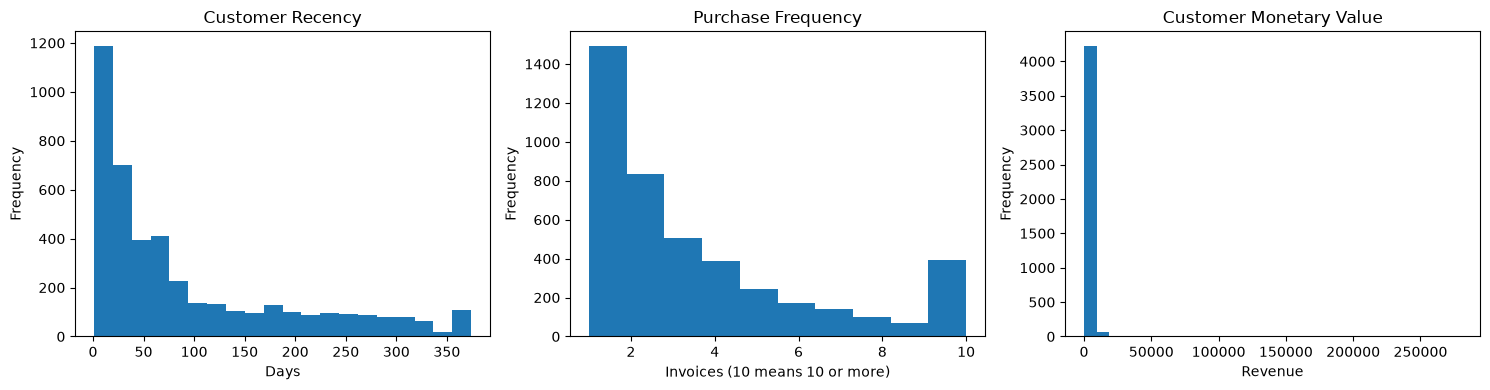

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rfm["Recency"].plot(
    kind="hist", bins=20, ax=axes[0]
)
axes[0].set_title("Customer Recency")
axes[0].set_xlabel("Days")

rfm["Frequency"].clip(upper=10).plot(
    kind="hist", bins=10, ax=axes[1]
)
axes[1].set_title("Purchase Frequency")
axes[1].set_xlabel("Invoices (10 means 10 or more)")

rfm["Monetary"].plot(
    kind="hist", bins=30, ax=axes[2]
)
axes[2].set_title("Customer Monetary Value")
axes[2].set_xlabel("Revenue")

plt.tight_layout()
plt.show()

In [17]:
rfm.to_csv("../data/customer_rfm.csv", index=False)

print("RFM results saved!")

RFM results saved!


In [18]:
conn.close()
print("Database connection closed.")

Database connection closed.


In [19]:
print("RFM shape:", rfm.shape)

print("\nRFM summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

print("\nMissing values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())

RFM shape: (4338, 4)

RFM summary:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [20]:
print("Duplicate customer IDs:", rfm["CustomerID"].duplicated().sum())

print("Negative Recency:", (rfm["Recency"] < 0).sum())
print("Frequency below 1:", (rfm["Frequency"] < 1).sum())
print("Negative Monetary:", (rfm["Monetary"] < 0).sum())

print("\nSample RFM records:")
display(rfm.head(10))

Duplicate customer IDs: 0
Negative Recency: 0
Frequency below 1: 0
Negative Monetary: 0

Sample RFM records:


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


In [1]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.5
Pandas: 3.1.1
